In [1]:
import pandas as pd

columns = [
    'duration','protocol_type','service','flag','src_bytes','dst_bytes','land',
    'wrong_fragment','urgent','hot','num_failed_logins','logged_in','num_compromised',
    'root_shell','su_attempted','num_root','num_file_creations','num_shells',
    'num_access_files','num_outbound_cmds','is_host_login','is_guest_login','count',
    'srv_count','serror_rate','srv_serror_rate','rerror_rate','srv_rerror_rate',
    'same_srv_rate','diff_srv_rate','srv_diff_host_rate','dst_host_count',
    'dst_host_srv_count','dst_host_same_srv_rate','dst_host_diff_srv_rate',
    'dst_host_same_src_port_rate','dst_host_srv_diff_host_rate','dst_host_serror_rate',
    'dst_host_srv_serror_rate','dst_host_rerror_rate','dst_host_srv_rerror_rate',
    'label','difficulty'
]

train = pd.read_csv('data/KDDTrain+.txt', names=columns)
test = pd.read_csv('data/KDDTest+.txt', names=columns)

print(train.shape, test.shape)
print(train['label'].value_counts().head(10))

(125973, 43) (22544, 43)
label
normal         67343
neptune        41214
satan           3633
ipsweep         3599
portsweep       2931
smurf           2646
nmap            1493
back             956
teardrop         892
warezclient      890
Name: count, dtype: int64


In [2]:
# 1) Group attack types into 5 main classes
attack_map = {
    'normal': 'Normal',
    # DoS
    'neptune':'DoS','smurf':'DoS','back':'DoS','teardrop':'DoS','pod':'DoS','land':'DoS',
    'apache2':'DoS','udpstorm':'DoS','processtable':'DoS','mailbomb':'DoS',
    # Probe
    'satan':'Probe','ipsweep':'Probe','nmap':'Probe','portsweep':'Probe','mscan':'Probe','saint':'Probe',
    # R2L
    'guess_passwd':'R2L','ftp_write':'R2L','imap':'R2L','phf':'R2L','multihop':'R2L',
    'warezmaster':'R2L','warezclient':'R2L','spy':'R2L','xlock':'R2L','xsnoop':'R2L',
    'snmpguess':'R2L','snmpgetattack':'R2L','httptunnel':'R2L','sendmail':'R2L','named':'R2L','worm':'R2L',
    # U2R
    'buffer_overflow':'U2R','loadmodule':'U2R','perl':'U2R','rootkit':'U2R',
    'ps':'U2R','sqlattack':'U2R','xterm':'U2R'
}

train['attack_class'] = train['label'].map(attack_map)
test['attack_class'] = test['label'].map(attack_map)

# 2) Quick data check
print("Missing values in train:", train.isnull().sum().sum())
print("Duplicate rows in train:", train.duplicated().sum())

print("\nUnmapped attack types:")
print("Train:", train[train['attack_class'].isnull()]['label'].unique())
print("Test:", test[test['attack_class'].isnull()]['label'].unique())

print("\nClass distribution (train):")
print(train['attack_class'].value_counts())

print("\nClass distribution (test):")
print(test['attack_class'].value_counts())

Missing values in train: 0
Duplicate rows in train: 0

Unmapped attack types:
Train: <ArrowStringArray>
[]
Length: 0, dtype: str
Test: <ArrowStringArray>
[]
Length: 0, dtype: str

Class distribution (train):
attack_class
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64

Class distribution (test):
attack_class
Normal    9711
DoS       7458
R2L       2887
Probe     2421
U2R         67
Name: count, dtype: int64


In [3]:
# 1) Group attack types into 5 main classes
attack_map = {
    'normal': 'Normal',
    # DoS
    'neptune':'DoS','smurf':'DoS','back':'DoS','teardrop':'DoS','pod':'DoS','land':'DoS',
    'apache2':'DoS','udpstorm':'DoS','processtable':'DoS','mailbomb':'DoS',
    # Probe
    'satan':'Probe','ipsweep':'Probe','nmap':'Probe','portsweep':'Probe','mscan':'Probe','saint':'Probe',
    # R2L
    'guess_passwd':'R2L','ftp_write':'R2L','imap':'R2L','phf':'R2L','multihop':'R2L',
    'warezmaster':'R2L','warezclient':'R2L','spy':'R2L','xlock':'R2L','xsnoop':'R2L',
    'snmpguess':'R2L','snmpgetattack':'R2L','httptunnel':'R2L','sendmail':'R2L','named':'R2L','worm':'R2L',
    # U2R
    'buffer_overflow':'U2R','loadmodule':'U2R','perl':'U2R','rootkit':'U2R',
    'ps':'U2R','sqlattack':'U2R','xterm':'U2R'
}

train['attack_class'] = train['label'].map(attack_map)
test['attack_class'] = test['label'].map(attack_map)

# 2) Quick data check
print("Missing values in train:", train.isnull().sum().sum())
print("Duplicate rows in train:", train.duplicated().sum())

print("\nUnmapped attack types:")
print("Train:", train[train['attack_class'].isnull()]['label'].unique())
print("Test:", test[test['attack_class'].isnull()]['label'].unique())

print("\nClass distribution (train):")
print(train['attack_class'].value_counts())

print("\nClass distribution (test):")
print(test['attack_class'].value_counts())

Missing values in train: 0
Duplicate rows in train: 0

Unmapped attack types:
Train: <ArrowStringArray>
[]
Length: 0, dtype: str
Test: <ArrowStringArray>
[]
Length: 0, dtype: str

Class distribution (train):
attack_class
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64

Class distribution (test):
attack_class
Normal    9711
DoS       7458
R2L       2887
Probe     2421
U2R         67
Name: count, dtype: int64


In [4]:
# 1) Group attack types into 5 main classes
attack_map = {
    'normal': 'Normal',
    # DoS
    'neptune':'DoS','smurf':'DoS','back':'DoS','teardrop':'DoS','pod':'DoS','land':'DoS',
    'apache2':'DoS','udpstorm':'DoS','processtable':'DoS','mailbomb':'DoS',
    # Probe
    'satan':'Probe','ipsweep':'Probe','nmap':'Probe','portsweep':'Probe','mscan':'Probe','saint':'Probe',
    # R2L
    'guess_passwd':'R2L','ftp_write':'R2L','imap':'R2L','phf':'R2L','multihop':'R2L',
    'warezmaster':'R2L','warezclient':'R2L','spy':'R2L','xlock':'R2L','xsnoop':'R2L',
    'snmpguess':'R2L','snmpgetattack':'R2L','httptunnel':'R2L','sendmail':'R2L','named':'R2L','worm':'R2L',
    # U2R
    'buffer_overflow':'U2R','loadmodule':'U2R','perl':'U2R','rootkit':'U2R',
    'ps':'U2R','sqlattack':'U2R','xterm':'U2R'
}

train['attack_class'] = train['label'].map(attack_map)
test['attack_class'] = test['label'].map(attack_map)

# 2) Quick data check
print("Missing values in train:", train.isnull().sum().sum())
print("Duplicate rows in train:", train.duplicated().sum())

print("\nUnmapped attack types:")
print("Train:", train[train['attack_class'].isnull()]['label'].unique())
print("Test:", test[test['attack_class'].isnull()]['label'].unique())

print("\nClass distribution (train):")
print(train['attack_class'].value_counts())

print("\nClass distribution (test):")
print(test['attack_class'].value_counts())

Missing values in train: 0
Duplicate rows in train: 0

Unmapped attack types:
Train: <ArrowStringArray>
[]
Length: 0, dtype: str
Test: <ArrowStringArray>
[]
Length: 0, dtype: str

Class distribution (train):
attack_class
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64

Class distribution (test):
attack_class
Normal    9711
DoS       7458
R2L       2887
Probe     2421
U2R         67
Name: count, dtype: int64


In [5]:
# 1) Group attack types into 5 main classes
attack_map = {
    'normal': 'Normal',
    # DoS
    'neptune':'DoS','smurf':'DoS','back':'DoS','teardrop':'DoS','pod':'DoS','land':'DoS',
    'apache2':'DoS','udpstorm':'DoS','processtable':'DoS','mailbomb':'DoS',
    # Probe
    'satan':'Probe','ipsweep':'Probe','nmap':'Probe','portsweep':'Probe','mscan':'Probe','saint':'Probe',
    # R2L
    'guess_passwd':'R2L','ftp_write':'R2L','imap':'R2L','phf':'R2L','multihop':'R2L',
    'warezmaster':'R2L','warezclient':'R2L','spy':'R2L','xlock':'R2L','xsnoop':'R2L',
    'snmpguess':'R2L','snmpgetattack':'R2L','httptunnel':'R2L','sendmail':'R2L','named':'R2L','worm':'R2L',
    # U2R
    'buffer_overflow':'U2R','loadmodule':'U2R','perl':'U2R','rootkit':'U2R',
    'ps':'U2R','sqlattack':'U2R','xterm':'U2R'
}

train['attack_class'] = train['label'].map(attack_map)
test['attack_class'] = test['label'].map(attack_map)

# 2) Quick data check
print("Missing values in train:", train.isnull().sum().sum())
print("Duplicate rows in train:", train.duplicated().sum())

print("\nUnmapped attack types:")
print("Train:", train[train['attack_class'].isnull()]['label'].unique())
print("Test:", test[test['attack_class'].isnull()]['label'].unique())

print("\nClass distribution (train):")
print(train['attack_class'].value_counts())

print("\nClass distribution (test):")
print(test['attack_class'].value_counts())

Missing values in train: 0
Duplicate rows in train: 0

Unmapped attack types:
Train: <ArrowStringArray>
[]
Length: 0, dtype: str
Test: <ArrowStringArray>
[]
Length: 0, dtype: str

Class distribution (train):
attack_class
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64

Class distribution (test):
attack_class
Normal    9711
DoS       7458
R2L       2887
Probe     2421
U2R         67
Name: count, dtype: int64


In [6]:
# 1) Group attack types into 5 main classes
attack_map = {
    'normal': 'Normal',
    # DoS
    'neptune':'DoS','smurf':'DoS','back':'DoS','teardrop':'DoS','pod':'DoS','land':'DoS',
    'apache2':'DoS','udpstorm':'DoS','processtable':'DoS','mailbomb':'DoS',
    # Probe
    'satan':'Probe','ipsweep':'Probe','nmap':'Probe','portsweep':'Probe','mscan':'Probe','saint':'Probe',
    # R2L
    'guess_passwd':'R2L','ftp_write':'R2L','imap':'R2L','phf':'R2L','multihop':'R2L',
    'warezmaster':'R2L','warezclient':'R2L','spy':'R2L','xlock':'R2L','xsnoop':'R2L',
    'snmpguess':'R2L','snmpgetattack':'R2L','httptunnel':'R2L','sendmail':'R2L','named':'R2L','worm':'R2L',
    # U2R
    'buffer_overflow':'U2R','loadmodule':'U2R','perl':'U2R','rootkit':'U2R',
    'ps':'U2R','sqlattack':'U2R','xterm':'U2R'
}

train['attack_class'] = train['label'].map(attack_map)
test['attack_class'] = test['label'].map(attack_map)

# 2) Quick data check
print("Missing values in train:", train.isnull().sum().sum())
print("Duplicate rows in train:", train.duplicated().sum())

print("\nUnmapped attack types:")
print("Train:", train[train['attack_class'].isnull()]['label'].unique())
print("Test:", test[test['attack_class'].isnull()]['label'].unique())

print("\nClass distribution (train):")
print(train['attack_class'].value_counts())

print("\nClass distribution (test):")
print(test['attack_class'].value_counts())

Missing values in train: 0
Duplicate rows in train: 0

Unmapped attack types:
Train: <ArrowStringArray>
[]
Length: 0, dtype: str
Test: <ArrowStringArray>
[]
Length: 0, dtype: str

Class distribution (train):
attack_class
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64

Class distribution (test):
attack_class
Normal    9711
DoS       7458
R2L       2887
Probe     2421
U2R         67
Name: count, dtype: int64


In [7]:
import numpy as np
from sklearn.preprocessing import StandardScaler, LabelEncoder

# 1) Define categorical columns
cat_cols = ['protocol_type', 'service', 'flag']

# 2) One-hot encode train and test together so both get identical columns
combined = pd.concat([train, test], keys=['train', 'test'])
combined = pd.get_dummies(combined, columns=cat_cols)

train_enc = combined.xs('train').copy()
test_enc = combined.xs('test').copy()

# 3) Separate features and target
drop_cols = ['label', 'difficulty', 'attack_class']
X_train = train_enc.drop(columns=drop_cols).astype(float)
X_test = test_enc.drop(columns=drop_cols).astype(float)

le = LabelEncoder()
y_train = le.fit_transform(train['attack_class'])
y_test = le.transform(test['attack_class'])

# 4) Scale numeric features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5) Check results
print("X_train shape:", X_train_scaled.shape)
print("X_test shape:", X_test_scaled.shape)
print("Classes:", list(le.classes_))

X_train shape: (125973, 122)
X_test shape: (22544, 122)
Classes: ['DoS', 'Normal', 'Probe', 'R2L', 'U2R']


In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import time

# 1) Train
start = time.time()
rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
rf.fit(X_train_scaled, y_train)
print("Training time: %.1f seconds" % (time.time() - start))

# 2) Predict
y_pred = rf.predict(X_test_scaled)

# 3) Evaluate
print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=le.classes_, zero_division=0))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

Training time: 3.0 seconds

Accuracy: 0.7511533002129169

Classification report:
              precision    recall  f1-score   support

         DoS       0.96      0.80      0.87      7458
      Normal       0.65      0.97      0.78      9711
       Probe       0.81      0.60      0.69      2421
         R2L       0.95      0.02      0.04      2887
         U2R       0.33      0.01      0.03        67

    accuracy                           0.75     22544
   macro avg       0.74      0.48      0.48     22544
weighted avg       0.81      0.75      0.70     22544

Confusion matrix:
[[5961 1352  145    0    0]
 [  67 9456  187    0    1]
 [ 165  792 1464    0    0]
 [   0 2829    5   52    1]
 [   0   63    0    3    1]]


In [9]:
from imblearn.over_sampling import SMOTE
from sklearn.metrics import f1_score, recall_score

def evaluate(name, model, Xtr, ytr):
    model.fit(Xtr, ytr)
    pred = model.predict(X_test_scaled)
    print("=== %s ===" % name)
    print("Accuracy: %.4f | Macro F1: %.4f" % (accuracy_score(y_test, pred), f1_score(y_test, pred, average='macro')))
    print("Per-class recall:", dict(zip(le.classes_, recall_score(y_test, pred, average=None, zero_division=0).round(2))))
    print()

# Option 1: class weights
evaluate("RF + class_weight", RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42, class_weight='balanced'), X_train_scaled, y_train)

# Option 2: SMOTE (train only)
smote = SMOTE(random_state=42, k_neighbors=5)
X_sm, y_sm = smote.fit_resample(X_train_scaled, y_train)
print("After SMOTE:", np.bincount(y_sm))
evaluate("RF + SMOTE", RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42), X_sm, y_sm)

=== RF + class_weight ===
Accuracy: 0.7457 | Macro F1: 0.5089
Per-class recall: {'DoS': np.float64(0.78), 'Normal': np.float64(0.97), 'Probe': np.float64(0.62), 'R2L': np.float64(0.02), 'U2R': np.float64(0.09)}

After SMOTE: [67343 67343 67343 67343 67343]
=== RF + SMOTE ===
Accuracy: 0.7526 | Macro F1: 0.5446
Per-class recall: {'DoS': np.float64(0.75), 'Normal': np.float64(0.97), 'Probe': np.float64(0.72), 'R2L': np.float64(0.05), 'U2R': np.float64(0.13)}



src_bytes                      0.123273
same_srv_rate                  0.063230
dst_host_srv_serror_rate       0.058247
flag_SF                        0.055225
dst_host_serror_rate           0.051769
diff_srv_rate                  0.048688
dst_host_same_srv_rate         0.047702
dst_host_srv_count             0.045101
dst_host_diff_srv_rate         0.040749
dst_bytes                      0.040702
flag_S0                        0.040024
count                          0.036376
dst_host_same_src_port_rate    0.033207
logged_in                      0.028334
protocol_type_icmp             0.024874
serror_rate                    0.022315
dst_host_srv_diff_host_rate    0.021392
srv_count                      0.019643
dst_host_rerror_rate           0.018913
dst_host_count                 0.018015
dtype: float64


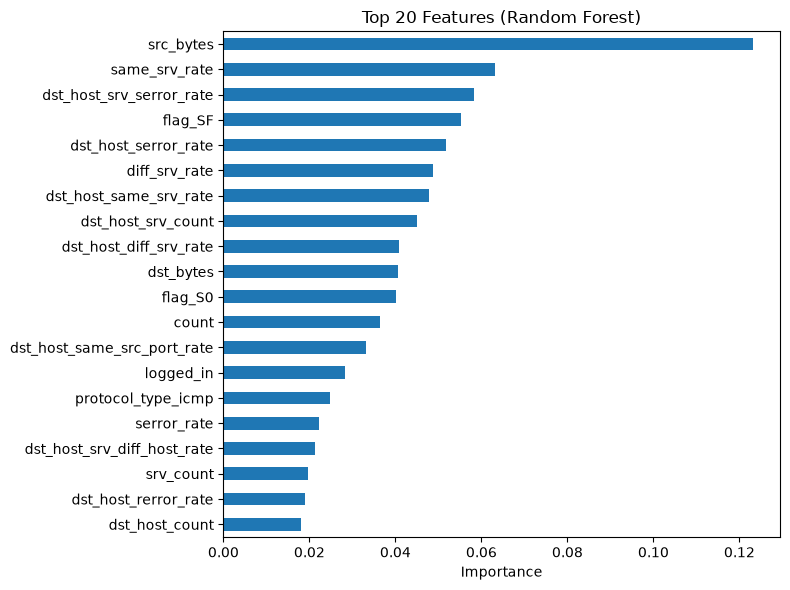


Top-30 features -> Accuracy: 0.7561 | Macro F1: 0.4973
Per-class recall: {'DoS': np.float64(0.8), 'Normal': np.float64(0.97), 'Probe': np.float64(0.63), 'R2L': np.float64(0.02), 'U2R': np.float64(0.03)}


In [10]:
import matplotlib.pyplot as plt

# 1) Feature importance from the baseline Random Forest
importances = pd.Series(rf.feature_importances_, index=X_train.columns)
top20 = importances.sort_values(ascending=False).head(20)
print(top20)

# 2) Plot top 20
plt.figure(figsize=(8, 6))
top20.sort_values().plot(kind='barh')
plt.title("Top 20 Features (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

# 3) Keep top 30 features and retrain
top_features = importances.sort_values(ascending=False).head(30).index
sel_idx = [X_train.columns.get_loc(c) for c in top_features]

X_train_sel = X_train_scaled[:, sel_idx]
X_test_sel = X_test_scaled[:, sel_idx]

rf_sel = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
rf_sel.fit(X_train_sel, y_train)
pred_sel = rf_sel.predict(X_test_sel)

print("\nTop-30 features -> Accuracy: %.4f | Macro F1: %.4f" % (
    accuracy_score(y_test, pred_sel), f1_score(y_test, pred_sel, average='macro')))
print("Per-class recall:", dict(zip(le.classes_, recall_score(y_test, pred_sel, average=None, zero_division=0).round(2))))